# PathSnap — Candidate Classifier: 5-Model Comparison

**Goal:** train and compare five candidate classifiers from different algorithm families. The chosen model's probabilities become the HMM/Viterbi emission scores later.

**Problem framing (candidate classification)**
1. Each GPS observation (sampled every `SAMPLE_EVERY` points) gets a **candidate set** of road arcs within `R_CAND` metres.
2. Each *(observation, candidate arc)* pair is one row, with label `y = 1` if the candidate is the reference arc for that observation and `0` otherwise.
3. The classifier outputs `P(y=1 | features)`. Taking the highest-scoring candidate per observation gives the **observation-level Top-1** prediction.

**Partitions used**
| Partition | Trips | Used for |
|---|---|---|
| `train` | 80 | fitting + 5-fold **GroupKFold** (grouped by trip) cross-validation |
| `student_test` | 10 | development-stage comparison only |
| evaluator test | 10 | **not used anywhere in this notebook** |

| Model | Family |
|---|---|
| Logistic Regression | Linear / probabilistic |
| Distance-weighted KNN | Instance-based |
| Random Forest | Bagging ensemble |
| LightGBM | Boosting |
| MLP | Neural network |

In [1]:
import os, json, time, warnings, platform
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import joblib

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)

SEED = 42
np.random.seed(SEED)

# ---------- paths (notebook lives in <repo>/model_comparison/) ----------
REPO_DIR = Path("..").resolve()
PROCESSED_DIR = REPO_DIR / "data" / "processed"     # cleaned CSVs from preprocessing/preprocess.py
RESULTS_DIR = Path("outputs").resolve()
CACHE_DIR = REPO_DIR / "cache"
MODELS_DIR = REPO_DIR / "models"
for d in (RESULTS_DIR, CACHE_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- pipeline configuration ----------
CFG = dict(
    R_CAND=50.0,        # candidate search radius (m)
    K_MAX=12,           # max candidates kept per observation (nearest first)
    SAMPLE_EVERY=5,     # use every 5th GPS fix (~5 s at 1 Hz)
    HEAD_H=2,           # half-window (fixes) for heading / speed estimation
    NB_OFF=3,           # offset (fixes) for previous/next context distances
    DENS_STEP=10.0,     # arc densification step for the KD-tree (m)
    MAX_HOPS=4,         # route-continuity: max directed hops between consecutive predictions
    N_FOLDS=5,
    SEED=SEED,
)
globals().update(CFG)
EARTH_R = 6371008.8

print("Processed data:", PROCESSED_DIR, "| exists:", PROCESSED_DIR.exists())
print("Results  :", RESULTS_DIR)
print("Python", platform.python_version(), "| lightgbm", lgb.__version__)

Processed data: /Users/Ananya/Downloads/mlhack/ml-hack-team15/data/processed | exists: True
Results  : /Users/Ananya/Downloads/mlhack/ml-hack-team15/model_comparison/outputs
Python 3.14.0 | lightgbm 4.7.0


## 1. Loading and projection

Input is the **cleaned data** produced by `preprocessing/preprocess.py`: `data/processed/<partition>/<trip>_{track,nodes,arcs,route}.csv`. In `track`, rows with NaNs, out-of-range coordinates or duplicate timestamps have been removed, and rows are sorted by time. In `nodes`/`arcs` the row index is still the `node_id`/`arc_id`. `route` lists the reference `arc_id`s (column `edge_id`) in travel order.

Distances in degrees are not metric, so every trip is projected to a **local equirectangular plane** centred on its mean GPS position. The error is negligible at city scale (a few km).

In [2]:
def read_arcs(split, tid):
    return pd.read_csv(PROCESSED_DIR / split / f"{tid}_arcs.csv")[["from_node_id", "to_node_id"]].to_numpy(np.int64)

def load_trip(split, tid):
    d = PROCESSED_DIR / split
    track = pd.read_csv(d / f"{tid}_track.csv")[["longitude", "latitude", "timestamp"]].to_numpy(float)
    nodes = pd.read_csv(d / f"{tid}_nodes.csv")[["longitude", "latitude"]].to_numpy(float)
    arcs = read_arcs(split, tid)
    route = pd.read_csv(d / f"{tid}_route.csv")["edge_id"].to_numpy(np.int64)
    return track, nodes, arcs, route

def project(lon, lat, lon0, lat0):
    x = np.radians(lon - lon0) * EARTH_R * np.cos(np.radians(lat0))
    y = np.radians(lat - lat0) * EARTH_R
    return np.c_[x, y]

def seg_dist(P, A, B):
    # Row-wise distance from points P to segments AB, plus the unclipped projection parameter t.
    AB = B - A
    L2 = np.einsum("ij,ij->i", AB, AB)
    t = np.einsum("ij,ij->i", P - A, AB) / np.where(L2 > 0, L2, 1)
    proj = A + AB * np.clip(t, 0, 1)[:, None]
    return np.linalg.norm(P - proj, axis=1), t

TRIPS = {s: sorted(p.name[:-len("_track.csv")] for p in (PROCESSED_DIR / s).glob("*_track.csv"))
         for s in ["train", "student_test"]}
print({k: len(v) for k, v in TRIPS.items()})

{'train': 80, 'student_test': 10}


## 2. Per-observation reference labels

`.route` lists the arcs in travel order but does **not** say which GPS fix belongs to which arc. We derive per-fix labels with a **monotone alignment (dynamic programming)**:

- `cost[i, j]` = distance (m) from fix *i* to route arc *j*.
- Each fix is assigned a route position `j_i` with `j_i ≥ j_{i-1}` (no going back along the route), minimising Σ cost. Skipping short arcs that received no fix is allowed.
- This takes O(N·M) time using a running prefix-minimum.

These labels are **derived reference labels**, not verified ground truth. Near intersections a fix can plausibly belong to either adjacent arc, and the alignment distance (`true_d`) is reported so label quality can be checked.

In [3]:
def label_points(pxy, Axy, Bxy, route):
    N, M = len(pxy), len(route)
    RA, RB = Axy[route], Bxy[route]
    AB = RB - RA
    L2 = np.where((AB ** 2).sum(1) > 0, (AB ** 2).sum(1), 1)
    cost = np.empty((N, M), dtype=np.float32)
    for s in range(0, N, 1000):
        P = pxy[s:s + 1000]
        t = np.clip(((P[:, None, :] - RA[None]) * AB[None]).sum(2) / L2, 0, 1)
        cost[s:s + 1000] = np.linalg.norm(P[:, None, :] - (RA[None] + AB[None] * t[..., None]), axis=2)
    back = np.zeros((N, M), dtype=np.int32)
    idx = np.arange(M)
    prev = cost[0].astype(np.float64)
    for i in range(1, N):
        pm = np.minimum.accumulate(prev)
        back[i] = np.maximum.accumulate(np.where(prev <= pm, idx, 0))   # argmin of prefix
        prev = cost[i] + pm
    j = int(np.argmin(prev)); pos = np.empty(N, dtype=np.int64)
    for i in range(N - 1, -1, -1):
        pos[i] = j
        j = back[i, j]
    return route[pos], cost[np.arange(N), pos]

## 3. Candidate generation and feature engineering

**Candidates:** every arc is densified to points spaced ≤ `DENS_STEP` m apart and put into a KD-tree. Each sampled fix queries radius `R_CAND + DENS_STEP/2`. Exact point-to-segment distances are then computed, and the `K_MAX` nearest arcs within `R_CAND` are kept. Two-way roads appear as **two arcs with identical geometry but opposite direction**, so heading features are essential.

| Feature | Meaning | Why |
|---|---|---|
| `dist` | perpendicular distance fix → arc (m) | GPS noise is roughly Gaussian around the true road |
| `rank`, `dist_rel`, `n_cand` | rank / distance relative to the closest candidate / candidate count | makes scores comparable within an observation |
| `head_diff`, `head_rel` | angle between GPS motion bearing and arc bearing (0–180°) | separates the two directions of a road and parallel streets |
| `speed`, `disp`, `turn`, `dt_prev` | motion state | heading is unreliable when stationary; gaps mean higher uncertainty |
| `t_clip`, `t_out` | projection position along the arc, metres beyond its ends | a fix projecting past an arc's end probably belongs to the next arc |
| `arc_len` | arc length (m) | long arcs collect more fixes |
| `dist_prev`, `dist_next`, `ctx_dist`, `ctx_rel` | distance of the fixes ±`NB_OFF` to the **same** arc | short-range temporal context: a true arc stays close for neighbouring fixes |

All features use only GPS + road network data, never the labels, so they can be computed identically inside the API at inference time.

In [4]:
FEATURES = ["dist", "rank", "dist_rel", "n_cand", "head_diff", "head_rel", "speed", "disp", "turn",
            "dt_prev", "t_clip", "t_out", "arc_len", "dist_prev", "dist_next", "ctx_dist", "ctx_rel"]

def _bearing(v):
    return np.degrees(np.arctan2(v[:, 0], v[:, 1])) % 360

def build_trip(split, tid, with_labels=True):
    track, nodes, arcs, route = load_trip(split, tid)
    lon0, lat0 = track[:, 0].mean(), track[:, 1].mean()
    pxy = project(track[:, 0], track[:, 1], lon0, lat0)
    nxy = project(nodes[:, 0], nodes[:, 1], lon0, lat0)
    Axy, Bxy = nxy[arcs[:, 0]], nxy[arcs[:, 1]]
    N, ts = len(pxy), track[:, 2]
    if with_labels:
        true_arc, true_d = label_points(pxy, Axy, Bxy, route)

    # spatial index over arcs near the trajectory
    lo, hi = pxy.min(0) - R_CAND - 50, pxy.max(0) + R_CAND + 50
    amin, amax = np.minimum(Axy, Bxy), np.maximum(Axy, Bxy)
    keep = np.where((amax[:, 0] >= lo[0]) & (amin[:, 0] <= hi[0]) & (amax[:, 1] >= lo[1]) & (amin[:, 1] <= hi[1]))[0]
    L = np.linalg.norm(Bxy[keep] - Axy[keep], axis=1)
    n = np.maximum(1, np.ceil(L / DENS_STEP).astype(int))
    rep = np.repeat(np.arange(len(keep)), n + 1)
    frac = np.concatenate([np.arange(m + 1) / m for m in n])
    tree = cKDTree(Axy[keep][rep] + (Bxy[keep][rep] - Axy[keep][rep]) * frac[:, None])

    # motion features on the raw 1 Hz sequence
    ar = np.arange(N)
    im, ip = np.clip(ar - HEAD_H, 0, N - 1), np.clip(ar + HEAD_H, 0, N - 1)
    dv = pxy[ip] - pxy[im]
    disp = np.linalg.norm(dv, axis=1)
    speed = np.clip(disp / np.maximum(ts[ip] - ts[im], 1e-3), 0, 70)
    gps_head = _bearing(dv)
    dt_prev = np.clip(np.r_[0, np.diff(ts)], 0, 300)
    turn = np.zeros(N)
    if N > 2:
        turn[1:-1] = np.abs((_bearing(pxy[2:] - pxy[1:-1]) - _bearing(pxy[1:-1] - pxy[:-2]) + 180) % 360 - 180)

    sidx = np.arange(0, N, SAMPLE_EVERY)
    meta = pd.DataFrame({"trip": tid, "pt": sidx})
    if with_labels:
        meta["true_arc"] = true_arc[sidx]; meta["true_d"] = true_d[sidx]

    hits = tree.query_ball_point(pxy[sidx], r=R_CAND + DENS_STEP / 2 + 1)
    P, A = [], []
    for si, h in zip(sidx, hits):
        if h:
            a = np.unique(keep[rep[h]]); P.append(np.full(len(a), si)); A.append(a)
    if not P:
        return pd.DataFrame(columns=["trip", "pt", "arc"] + FEATURES), meta
    P, A = np.concatenate(P), np.concatenate(A)
    d, t = seg_dist(pxy[P], Axy[A], Bxy[A])
    m = d <= R_CAND
    df = pd.DataFrame({"trip": tid, "pt": P[m], "arc": A[m], "dist": d[m], "t": t[m]}).sort_values(["pt", "dist"])
    df["rank"] = df.groupby("pt").cumcount()
    df = df[df["rank"] < K_MAX].reset_index(drop=True)
    P, A = df["pt"].values, df["arc"].values

    av = Bxy[A] - Axy[A]
    df["arc_len"] = np.linalg.norm(av, axis=1)
    df["head_diff"] = np.abs((gps_head[P] - _bearing(av) + 180) % 360 - 180)
    df["speed"], df["disp"], df["dt_prev"], df["turn"] = speed[P], disp[P], dt_prev[P], turn[P]
    df["t_clip"] = df["t"].clip(0, 1)
    df["t_out"] = np.maximum(0, np.maximum(-df["t"], df["t"] - 1)) * df["arc_len"]
    df["dist_prev"], _ = seg_dist(pxy[np.clip(P - NB_OFF, 0, N - 1)], Axy[A], Bxy[A])
    df["dist_next"], _ = seg_dist(pxy[np.clip(P + NB_OFF, 0, N - 1)], Axy[A], Bxy[A])
    df["ctx_dist"] = (df["dist"] + df["dist_prev"] + df["dist_next"]) / 3
    g = df.groupby("pt")
    df["n_cand"] = g["arc"].transform("size")
    df["dist_rel"] = df["dist"] - g["dist"].transform("min")
    df["head_rel"] = df["head_diff"] - g["head_diff"].transform("min")
    df["ctx_rel"] = df["ctx_dist"] - g["ctx_dist"].transform("min")
    if with_labels:
        df["y"] = (df["arc"].values == true_arc[P]).astype(np.int8)
    return df.drop(columns="t"), meta

### Build (or load cached) datasets

In [5]:
def build_split(split):
    cache = CACHE_DIR / f"{split}_S{SAMPLE_EVERY}_R{int(R_CAND)}_K{K_MAX}.pkl"
    if cache.exists():
        return pd.read_pickle(cache)
    t0 = time.time(); dfs, metas = [], []
    for tid in TRIPS[split]:
        df, meta = build_trip(split, tid)
        dfs.append(df); metas.append(meta)
    out = (pd.concat(dfs, ignore_index=True), pd.concat(metas, ignore_index=True))
    pd.to_pickle(out, cache)
    print(f"{split}: built in {time.time() - t0:.1f}s")
    return out

train_df, train_meta = build_split("train")
test_df, test_meta = build_split("student_test")

def coverage(df, meta):
    hit = df[df.y == 1][["trip", "pt"]].drop_duplicates().assign(hit=1)
    m = meta.merge(hit, on=["trip", "pt"], how="left").fillna({"hit": 0})
    return m

summary = []
for name, df, meta in [("train", train_df, train_meta), ("student_test", test_df, test_meta)]:
    cov = coverage(df, meta)
    summary.append(dict(partition=name, trips=meta.trip.nunique(), observations=len(meta),
                        obs_with_candidates=df[["trip", "pt"]].drop_duplicates().shape[0],
                        candidate_rows=len(df), cand_per_obs=round(df.groupby(["trip", "pt"]).size().mean(), 2),
                        positive_rate=round(df.y.mean(), 4),
                        candidate_miss_rate=round(1 - cov.hit.mean(), 4),
                        label_dist_median_m=round(meta.true_d.median(), 2),
                        label_dist_p95_m=round(meta.true_d.quantile(.95), 2)))
summary = pd.DataFrame(summary)
summary.to_csv(RESULTS_DIR / "dataset_summary.csv", index=False)
summary

train: built in 17.3s


student_test: built in 1.1s


,partition,trips,observations,obs_with_candidates,candidate_rows,cand_per_obs,positive_rate,candidate_miss_rate,label_dist_median_m,label_dist_p95_m
0,train,80,41713,38066,269043,7.07,0.1370,0.1162,5.63,142.30
1,student_test,10,3836,3836,29512,7.69,0.1298,0.0016,5.06,16.82


### Data-quality filter (training partition only)
Some training trips have a reference route that does not match their GPS track: the median distance from fix to aligned route arc is far beyond any plausible GPS error. Their labels are unusable, because nearly every candidate becomes a "negative". Trips whose **median** label distance exceeds `R_CAND` are dropped from fitting and CV. The rule is defined on training data only. Student-test trips are never filtered.

In [6]:
trip_q = train_meta.groupby("trip")["true_d"].median()
BAD_TRIPS = sorted(trip_q[trip_q > R_CAND].index)
print("Excluded training trips (median label distance > R_CAND):", {t: round(trip_q[t], 1) for t in BAD_TRIPS})
train_df = train_df[~train_df.trip.isin(BAD_TRIPS)].reset_index(drop=True)
train_meta = train_meta[~train_meta.trip.isin(BAD_TRIPS)].reset_index(drop=True)
TRIPS["train_used"] = [t for t in TRIPS["train"] if t not in BAD_TRIPS]
cov = coverage(train_df, train_meta)
print(f"Train after filter: {train_meta.trip.nunique()} trips, {len(train_df)} candidate rows, "
      f"candidate miss rate {1 - cov.hit.mean():.4f}")
json.dump(dict(excluded=BAD_TRIPS, median_label_dist={t: float(trip_q[t]) for t in BAD_TRIPS}),
          open(RESULTS_DIR / "excluded_trips.json", "w"), indent=2)

Excluded training trips (median label distance > R_CAND): {'00000033': np.float32(122.3), '00000054': np.float32(139.9)}
Train after filter: 78 trips, 255788 candidate rows, candidate miss rate 0.0153


**Candidate miss rate** is the fraction of observations whose reference arc is *not* in the candidate set. No classifier can get those right, so `1 − miss rate` is the upper bound on Top-1.

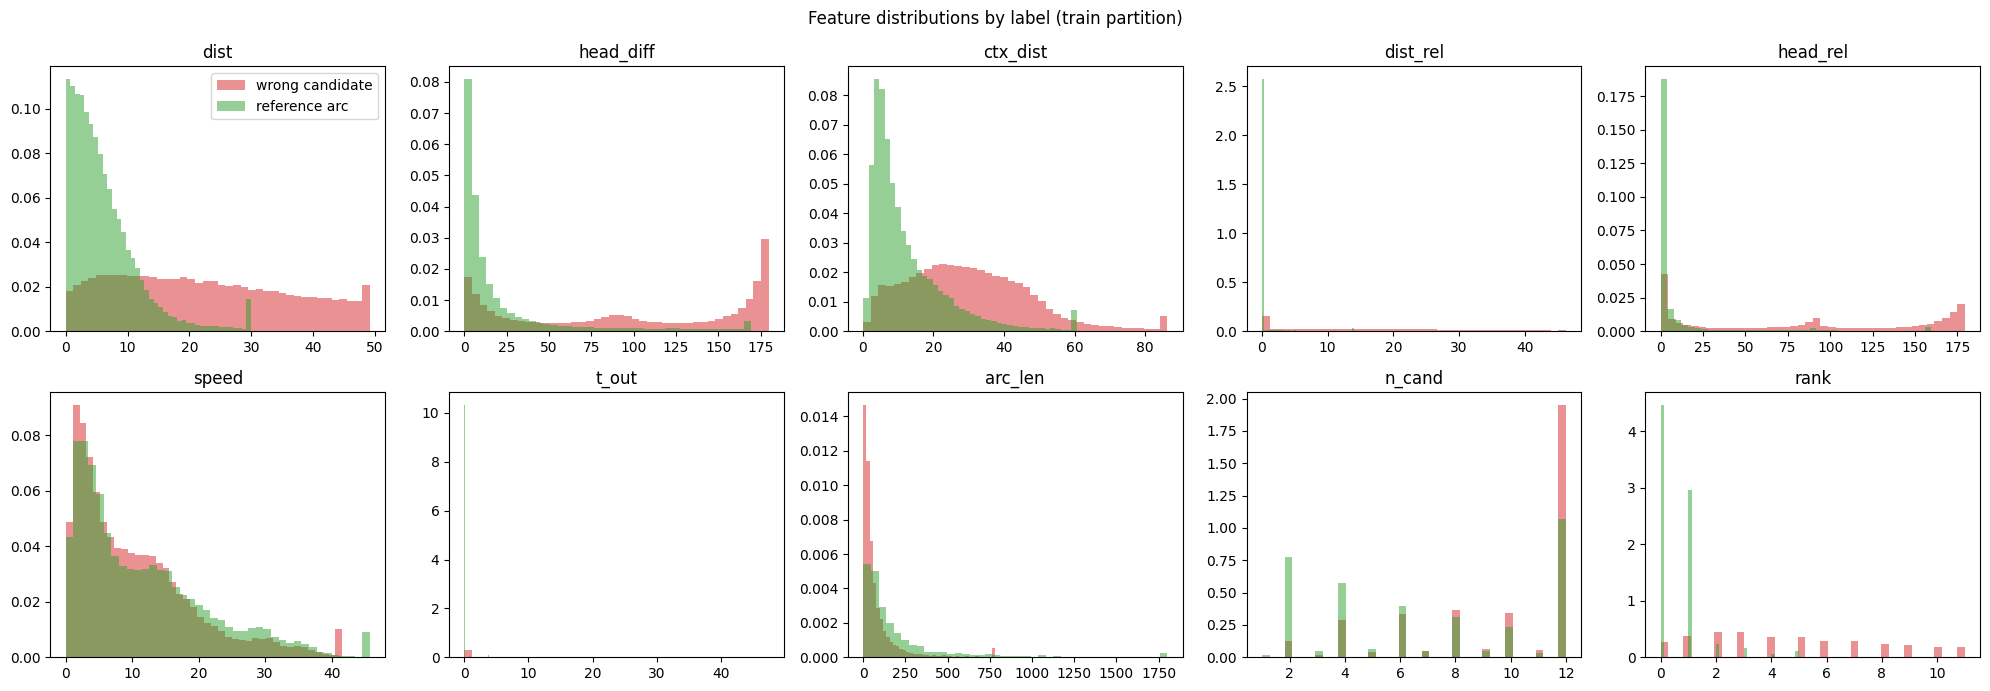

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, f in zip(axes.ravel(), ["dist", "head_diff", "ctx_dist", "dist_rel", "head_rel", "speed", "t_out", "arc_len", "n_cand", "rank"]):
    for y, c, lab in [(0, "tab:red", "wrong candidate"), (1, "tab:green", "reference arc")]:
        v = train_df.loc[train_df.y == y, f]
        ax.hist(v.clip(upper=v.quantile(.99)), bins=40, density=True, alpha=.5, color=c, label=lab)
    ax.set_title(f)
axes[0, 0].legend()
fig.suptitle("Feature distributions by label (train partition)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_distributions.png", dpi=120); plt.show()

## 4. Evaluation metrics

| Metric | Level | Definition |
|---|---|---|
| Accuracy / Precision / Recall / **Macro F1** / Log Loss | candidate row | binary `y` vs `P ≥ 0.5` (macro F1 averages over classes 0 and 1, so it is not dominated by the many negatives) |
| **Top-1 accuracy** (primary) | observation | highest-probability candidate == reference arc; observations with no correct candidate count as **wrong** |
| Top-1 (covered) | observation | same, but only over observations whose reference arc was among the candidates |
| **Route continuity** | sequence | share of consecutive Top-1 predictions (`SAMPLE_EVERY` s apart) that are the same arc or reachable within `MAX_HOPS` directed hops in the road graph |
| Per-trip Top-1 | sequence | Top-1 computed per trip, to show the spread between trips |

**Primary selection metric: CV Top-1 accuracy.** This is the decision the decoder actually depends on: whether the right arc ranks first within each observation. Log loss is used as a secondary check, because the HMM consumes the probabilities themselves.

In [8]:
_GRAPH = {}
def get_graph(split, tid):
    if tid not in _GRAPH:
        arcs = read_arcs(split, tid)
        order = np.argsort(arcs[:, 0], kind="stable")
        start = np.searchsorted(arcs[order, 0], np.arange(arcs[:, :2].max() + 2))
        _GRAPH[tid] = (arcs, order, start)
    return _GRAPH[tid]

def reachable(a, b, graph, max_hops=MAX_HOPS):
    arcs, order, start = graph
    frontier = {a}
    for _ in range(max_hops):
        nxt = set()
        for x in frontier:
            nd = arcs[x, 1]
            outs = order[start[nd]:start[nd + 1]]
            if b in outs:
                return True
            nxt.update(outs.tolist())
        frontier = nxt
    return False

def route_continuity(seq_df, split):
    # seq_df: columns trip, pt, arc (one predicted arc per observation)
    ok = tot = 0
    for tid, g in seq_df.sort_values(["trip", "pt"]).groupby("trip"):
        a = g["arc"].values
        graph = get_graph(split, tid)
        for x, y in zip(a[:-1], a[1:]):
            tot += 1
            ok += (x == y) or reachable(int(x), int(y), graph)
    return ok / max(tot, 1)

def evaluate(df, meta, proba, split, with_continuity=True):
    y = df["y"].values
    yhat = (proba >= 0.5).astype(int)
    p = np.clip(proba, 1e-7, 1 - 1e-7)
    r = dict(accuracy=accuracy_score(y, yhat),
             precision=precision_score(y, yhat, zero_division=0),
             recall=recall_score(y, yhat, zero_division=0),
             f1_pos=f1_score(y, yhat, zero_division=0),
             macro_f1=f1_score(y, yhat, average="macro", zero_division=0),
             log_loss=log_loss(y, p, labels=[0, 1]))
    tmp = df[["trip", "pt", "arc", "y"]].copy(); tmp["p"] = proba
    top = tmp.loc[tmp.groupby(["trip", "pt"])["p"].idxmax()]
    r["top1"] = top["y"].sum() / len(meta)
    r["top1_covered"] = top["y"].mean()
    per_trip = (top.groupby("trip")["y"].sum() / meta.groupby("trip").size()).fillna(0)
    r["top1_trip_mean"], r["top1_trip_min"] = per_trip.mean(), per_trip.min()
    if with_continuity:
        r["route_continuity"] = route_continuity(top, split)
    return r, top, per_trip, confusion_matrix(y, yhat, labels=[0, 1])

# sanity check: continuity of the *reference* labels (should be ~1)
ref_seq = test_meta.rename(columns={"true_arc": "arc"})
print("Reference-label route continuity (student_test):", round(route_continuity(ref_seq, "student_test"), 4))

Reference-label route continuity (student_test): 0.9773


### Heuristic reference point (not one of the 5 models)
Always pick the nearest candidate. A learned model has to beat this to be worth anything.

In [9]:
nearest_proba = (test_df["rank"].values == 0).astype(float)
nearest_res, *_ = evaluate(test_df, test_meta, nearest_proba, "student_test")
{k: round(v, 4) for k, v in nearest_res.items()}

{'accuracy': 0.8796,
 'precision': 0.536,
 'recall': 0.5368,
 'f1_pos': 0.5364,
 'macro_f1': 0.7336,
 'log_loss': 1.941,
 'top1': np.float64(0.536),
 'top1_covered': np.float64(0.536),
 'top1_trip_mean': np.float64(0.5582),
 'top1_trip_min': np.float64(0.4087),
 'route_continuity': np.float64(0.9077)}

## 5. The five models

Configurations are **untuned defaults chosen a priori**. Bayesian optimisation is applied to the selected model in a later notebook. Linear, distance-based and neural models get a `StandardScaler`, fit inside the pipeline so scaling is learned only from the training fold. Trees don't need scaling.

In [10]:
MODELS = {
    "LogisticRegression": ("Linear / probabilistic", make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))),
    "KNN (distance-weighted)": ("Instance-based", make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1))),
    "RandomForest": ("Bagging ensemble", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED)),
    "LightGBM": ("Boosting", lgb.LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)),
    "MLP": ("Neural network", make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4,
                                        batch_size=512, learning_rate_init=1e-3, max_iter=200,
                                        early_stopping=True, n_iter_no_change=10, random_state=SEED))),
}

def short_cfg(est):
    keys = ["C", "n_neighbors", "weights", "n_estimators", "min_samples_leaf", "max_features", "learning_rate",
            "num_leaves", "hidden_layer_sizes", "alpha", "early_stopping"]
    params = est.get_params()
    return ", ".join(f"{k.split('__')[-1]}={params[k]}" for k in params if k.split("__")[-1] in keys)

configs = {name: {k: str(v) for k, v in est.get_params().items()} for name, (_, est) in MODELS.items()}
json.dump(dict(pipeline=CFG, features=FEATURES, models=configs), open(RESULTS_DIR / "experiment_config.json", "w"), indent=2)
pd.DataFrame([(n, f, short_cfg(e)) for n, (f, e) in MODELS.items()], columns=["model", "family", "key config"])

,model,family,key config
0,LogisticRegression,Linear / probabilistic,C=1.0
1,KNN (distance-weighted),Instance-based,"n_neighbors=25, weights=distance"
2,RandomForest,Bagging ensemble,"max_features=sqrt, min_samples_leaf=5, n_estim..."
3,LightGBM,Boosting,"learning_rate=0.05, n_estimators=400, num_leav..."
4,MLP,Neural network,"alpha=0.0001, early_stopping=True, hidden_laye..."


## 6. Group-aware 5-fold cross-validation (80 training trips)

`GroupKFold` with `groups = trip` keeps every trip entirely in either the training or validation side of a fold, so there is no leakage between neighbouring, nearly identical fixes.

In [11]:
X_tr, y_tr, g_tr = train_df[FEATURES].values, train_df["y"].values, train_df["trip"].values
gkf = GroupKFold(n_splits=N_FOLDS)
folds = list(gkf.split(X_tr, y_tr, g_tr))

cv_rows = []
for name, (family, est) in MODELS.items():
    for k, (tr_i, va_i) in enumerate(folds):
        m = clone(est)
        t0 = time.perf_counter(); m.fit(X_tr[tr_i], y_tr[tr_i]); fit_t = time.perf_counter() - t0
        va_df = train_df.iloc[va_i]
        va_meta = train_meta[train_meta.trip.isin(np.unique(g_tr[va_i]))]
        t0 = time.perf_counter(); p = m.predict_proba(X_tr[va_i])[:, 1]; pred_t = time.perf_counter() - t0
        r, *_ = evaluate(va_df, va_meta, p, "train", with_continuity=False)
        cv_rows.append(dict(model=name, fold=k, fit_s=fit_t, predict_s=pred_t, **r))
    last = pd.DataFrame(cv_rows).query("model == @name")
    print(f"{name:26s} CV macroF1 {last.macro_f1.mean():.4f}±{last.macro_f1.std():.4f} | "
          f"Top-1 {last.top1.mean():.4f}±{last.top1.std():.4f} | logloss {last.log_loss.mean():.4f} | fit {last.fit_s.mean():.1f}s/fold")

cv = pd.DataFrame(cv_rows)
cv.to_csv(RESULTS_DIR / "cv_folds.csv", index=False)
cv_summary = cv.groupby("model", sort=False).agg(
    cv_macro_f1=("macro_f1", "mean"), cv_macro_f1_std=("macro_f1", "std"),
    cv_top1=("top1", "mean"), cv_top1_std=("top1", "std"),
    cv_log_loss=("log_loss", "mean"), fit_s_per_fold=("fit_s", "mean"))
cv_summary.round(4)

LogisticRegression         CV macroF1 0.9171±0.0289 | Top-1 0.8644±0.0576 | logloss 0.1149 | fit 0.2s/fold


KNN (distance-weighted)    CV macroF1 0.9157±0.0314 | Top-1 0.8616±0.0588 | logloss 0.1333 | fit 0.0s/fold


RandomForest               CV macroF1 0.9286±0.0276 | Top-1 0.8764±0.0553 | logloss 0.0859 | fit 34.3s/fold


LightGBM                   CV macroF1 0.9276±0.0284 | Top-1 0.8744±0.0551 | logloss 0.0849 | fit 2.8s/fold


MLP                        CV macroF1 0.9244±0.0295 | Top-1 0.8749±0.0563 | logloss 0.0893 | fit 5.8s/fold


,cv_macro_f1,cv_macro_f1_std,cv_top1,cv_top1_std,cv_log_loss,fit_s_per_fold
model,,,,,,
LogisticRegression,0.9171,0.0289,0.8644,0.0576,0.1149,0.2496
KNN (distance-weighted),0.9157,0.0314,0.8616,0.0588,0.1333,0.0408
RandomForest,0.9286,0.0276,0.8764,0.0553,0.0859,34.3491
LightGBM,0.9276,0.0284,0.8744,0.0551,0.0849,2.7790
MLP,0.9244,0.0295,0.8749,0.0563,0.0893,5.8383


## 7. Refit on all 80 training trips → evaluate on the 10 student-testing trips

Training-set scores are computed on a fixed random subset of 20 training trips to keep KNN prediction tractable. They are compared against CV and student-test scores to diagnose over- and underfitting.

In [12]:
X_te = test_df[FEATURES].values
rng = np.random.RandomState(SEED)
tr_sub_trips = rng.choice(TRIPS["train_used"], 20, replace=False)
tr_sub = train_df[train_df.trip.isin(tr_sub_trips)]
tr_sub_meta = train_meta[train_meta.trip.isin(tr_sub_trips)]

fitted, test_rows, test_probs, test_tops, per_trip_all, cms = {}, [], {}, {}, {}, {}
for name, (family, est) in MODELS.items():
    m = clone(est)
    t0 = time.perf_counter(); m.fit(X_tr, y_tr); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); p = m.predict_proba(X_te)[:, 1]; inf_t = time.perf_counter() - t0
    r, top, per_trip, cm = evaluate(test_df, test_meta, p, "student_test")
    r_tr, *_ = evaluate(tr_sub, tr_sub_meta, m.predict_proba(tr_sub[FEATURES].values)[:, 1], "train", with_continuity=False)
    fitted[name], test_probs[name], test_tops[name], per_trip_all[name], cms[name] = m, p, top, per_trip, cm
    test_rows.append(dict(model=name, family=family, fit_s_full=fit_t, inference_s=inf_t,
                          inference_ms_per_1k_rows=1000 * inf_t / len(X_te) * 1000,
                          train_macro_f1=r_tr["macro_f1"], train_top1=r_tr["top1"],
                          **{f"test_{k}": v for k, v in r.items()}))
    print(f"{name:26s} test Top-1 {r['top1']:.4f} | macroF1 {r['macro_f1']:.4f} | logloss {r['log_loss']:.4f} | "
          f"continuity {r['route_continuity']:.4f} | fit {fit_t:.1f}s | infer {inf_t:.2f}s")

test_res = pd.DataFrame(test_rows).set_index("model")
pd.DataFrame(per_trip_all).to_csv(RESULTS_DIR / "student_test_per_trip_top1.csv")

LogisticRegression         test Top-1 0.8738 | macroF1 0.9146 | logloss 0.1067 | continuity 0.9550 | fit 0.3s | infer 0.00s


KNN (distance-weighted)    test Top-1 0.8746 | macroF1 0.9158 | logloss 0.1076 | continuity 0.9553 | fit 0.0s | infer 3.75s


RandomForest               test Top-1 0.8863 | macroF1 0.9306 | logloss 0.0745 | continuity 0.9592 | fit 48.1s | infer 0.13s


LightGBM                   test Top-1 0.8879 | macroF1 0.9316 | logloss 0.0723 | continuity 0.9587 | fit 3.2s | infer 0.10s


MLP                        test Top-1 0.8814 | macroF1 0.9254 | logloss 0.0774 | continuity 0.9571 | fit 5.4s | infer 0.01s


## 8. Consolidated comparison table

In [13]:
comp = pd.DataFrame({
    "Algorithm family": test_res["family"],
    "Key configuration": [short_cfg(MODELS[n][1]) for n in test_res.index],
    "CV Macro F1 (mean±std)": [f"{cv_summary.loc[n, 'cv_macro_f1']:.4f} ± {cv_summary.loc[n, 'cv_macro_f1_std']:.4f}" for n in test_res.index],
    "CV Top-1": cv_summary.loc[test_res.index, "cv_top1"].round(4).values,
    "Student-test Top-1": test_res["test_top1"].round(4),
    "Route continuity": test_res["test_route_continuity"].round(4),
    "Student-test Macro F1": test_res["test_macro_f1"].round(4),
    "Precision (y=1)": test_res["test_precision"].round(4),
    "Recall (y=1)": test_res["test_recall"].round(4),
    "Log Loss": test_res["test_log_loss"].round(4),
    "Fit time (s)": test_res["fit_s_full"].round(2),
    "Inference time (s, student-test)": test_res["inference_s"].round(3),
})
comp.loc["Nearest-candidate heuristic"] = ["Heuristic", "argmin distance", "N/A (no training)", np.nan,
    round(nearest_res["top1"], 4), round(nearest_res["route_continuity"], 4), round(nearest_res["macro_f1"], 4),
    round(nearest_res["precision"], 4), round(nearest_res["recall"], 4), "N/A (hard 0/1 scores)", 0, np.nan]
comp.to_csv(RESULTS_DIR / "model_comparison_table.csv")
full = cv_summary.join(test_res.drop(columns="family"))
full.to_csv(RESULTS_DIR / "model_comparison_full_metrics.csv")
comp

,Algorithm family,Key configuration,CV Macro F1 (mean±std),CV Top-1,Student-test Top-1,Route continuity,Student-test Macro F1,Precision (y=1),Recall (y=1),Log Loss,Fit time (s),"Inference time (s, student-test)"
model,,,,,,,,,,,,
LogisticRegression,Linear / probabilistic,C=1.0,0.9171 ± 0.0289,0.8644,0.8738,0.9550,0.9146,0.8361,0.8681,0.1067,0.28,0.002
KNN (distance-weighted),Instance-based,"n_neighbors=25, weights=distance",0.9157 ± 0.0314,0.8616,0.8746,0.9553,0.9158,0.8580,0.8488,0.1076,0.04,3.747
RandomForest,Bagging ensemble,"max_features=sqrt, min_samples_leaf=5, n_estim...",0.9286 ± 0.0276,0.8764,0.8863,0.9592,0.9306,0.8911,0.8671,0.0745,48.08,0.130
LightGBM,Boosting,"learning_rate=0.05, n_estimators=400, num_leav...",0.9276 ± 0.0284,0.8744,0.8879,0.9587,0.9316,0.8863,0.8755,0.0723,3.20,0.097
MLP,Neural network,"alpha=0.0001, early_stopping=True, hidden_laye...",0.9244 ± 0.0295,0.8749,0.8814,0.9571,0.9254,0.8897,0.8507,0.0774,5.43,0.006
Nearest-candidate heuristic,Heuristic,argmin distance,N/A (no training),NaN,0.5360,0.9077,0.7336,0.5360,0.5368,N/A (hard 0/1 scores),0.00,NaN


## 9. Visual comparisons

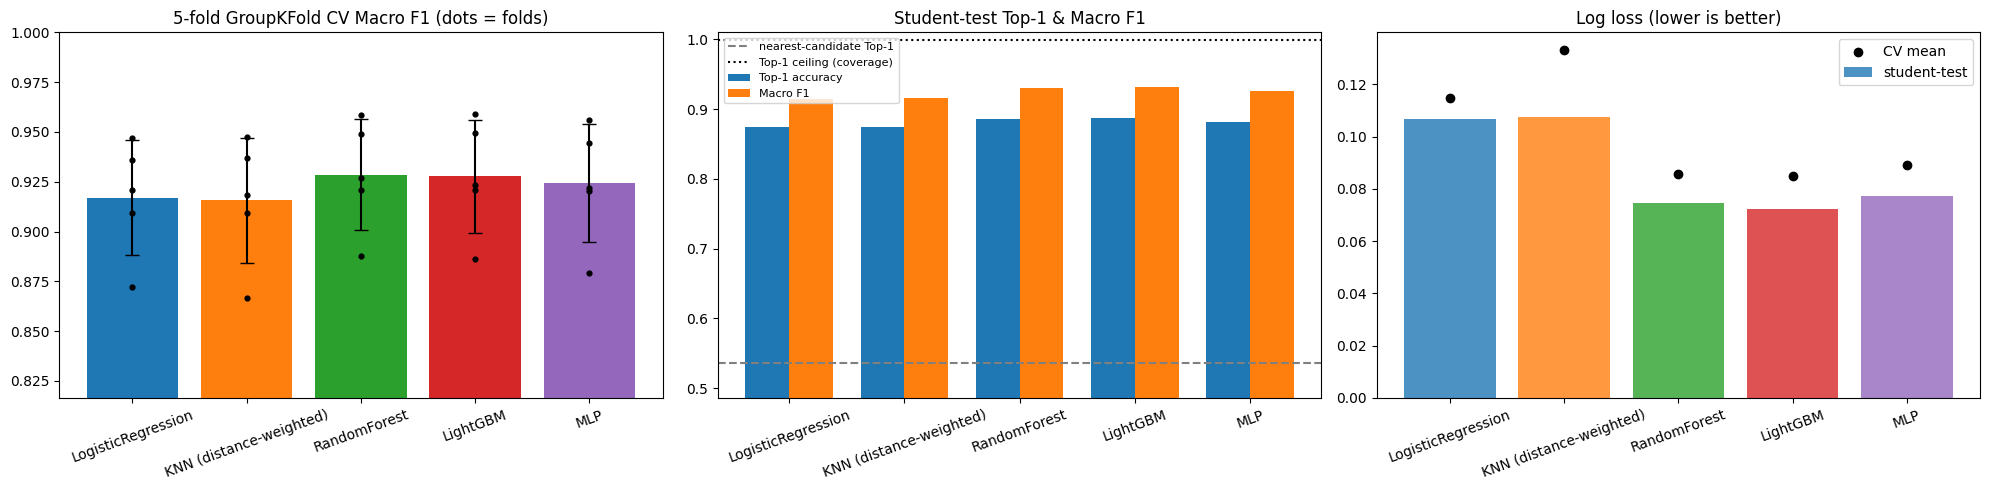

In [14]:
names = list(MODELS)
colors = plt.cm.tab10(np.arange(len(names)))
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

ax = axes[0]
ax.bar(names, cv_summary.loc[names, "cv_macro_f1"], yerr=cv_summary.loc[names, "cv_macro_f1_std"], color=colors, capsize=5)
for k, n in enumerate(names):
    ax.scatter([k] * N_FOLDS, cv.query("model == @n").macro_f1, color="k", s=12, zorder=3)
ax.set_title("5-fold GroupKFold CV Macro F1 (dots = folds)"); ax.set_ylim(cv.macro_f1.min() - .05, 1)

ax = axes[1]; w = .38; x = np.arange(len(names))
ax.bar(x - w / 2, test_res.loc[names, "test_top1"], w, label="Top-1 accuracy")
ax.bar(x + w / 2, test_res.loc[names, "test_macro_f1"], w, label="Macro F1")
ax.axhline(nearest_res["top1"], ls="--", c="grey", label="nearest-candidate Top-1")
ax.axhline(1 - summary.set_index("partition").loc["student_test", "candidate_miss_rate"], ls=":", c="k", label="Top-1 ceiling (coverage)")
ax.set_xticks(x, names); ax.set_title("Student-test Top-1 & Macro F1"); ax.legend(fontsize=8)
ax.set_ylim(min(test_res.test_top1.min(), test_res.test_macro_f1.min(), nearest_res["top1"]) - .05, 1.01)

ax = axes[2]
ax.bar(names, test_res.loc[names, "test_log_loss"], color=colors, alpha=.8, label="student-test")
ax.scatter(names, cv_summary.loc[names, "cv_log_loss"], color="k", zorder=3, label="CV mean")
ax.set_title("Log loss (lower is better)"); ax.legend()
for a in axes: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "comparison_metrics.png", dpi=120); plt.show()

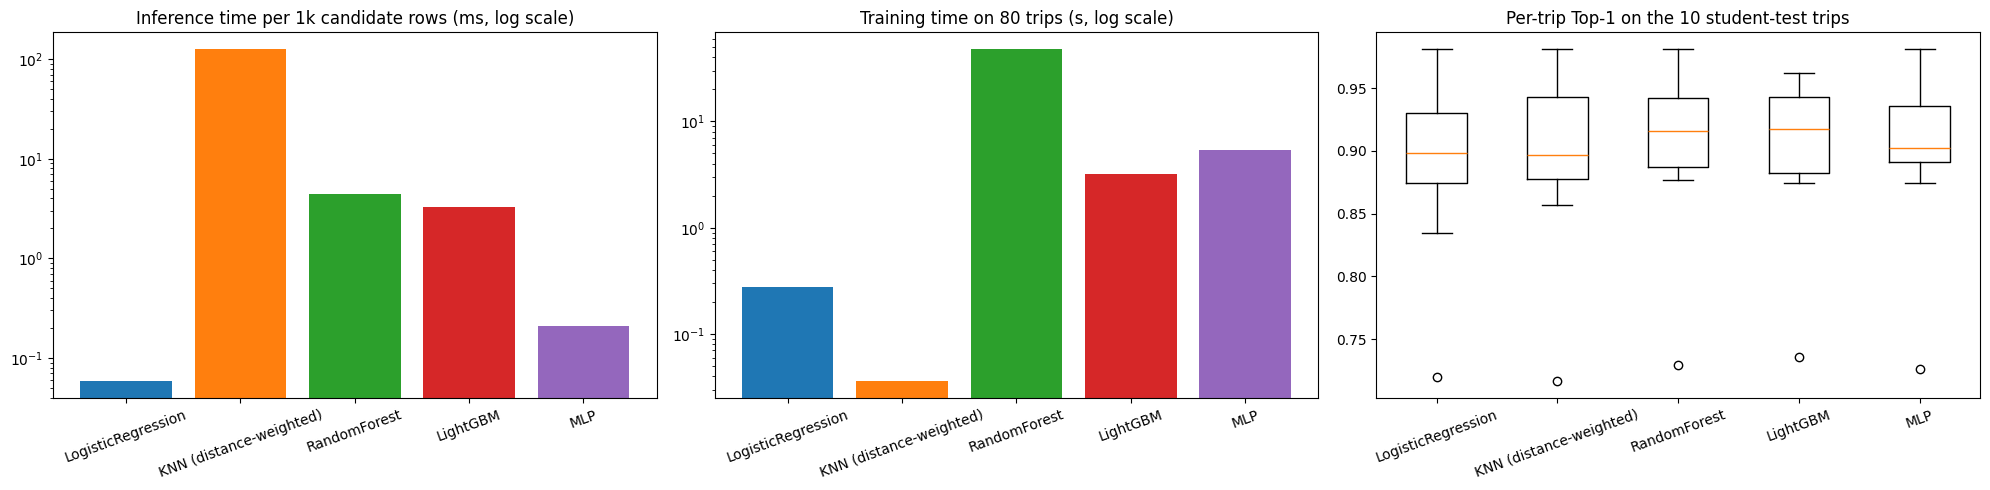

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
ax = axes[0]
ax.bar(names, test_res.loc[names, "inference_ms_per_1k_rows"], color=colors); ax.set_yscale("log")
ax.set_title("Inference time per 1k candidate rows (ms, log scale)")
ax = axes[1]
ax.bar(names, test_res.loc[names, "fit_s_full"], color=colors); ax.set_yscale("log")
ax.set_title("Training time on 80 trips (s, log scale)")
ax = axes[2]
ax.boxplot([per_trip_all[n].values for n in names], tick_labels=names)
ax.set_title("Per-trip Top-1 on the 10 student-test trips")
for a in axes: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "efficiency_and_per_trip.png", dpi=120); plt.show()

### Over/underfitting check: train-subset vs CV vs student-test
A big gap between train and CV/test suggests overfitting. Low scores everywhere suggest underfitting. Note that distance-weighted KNN scores ~100% on its own training points by construction, because each point's own neighbour is at distance 0.

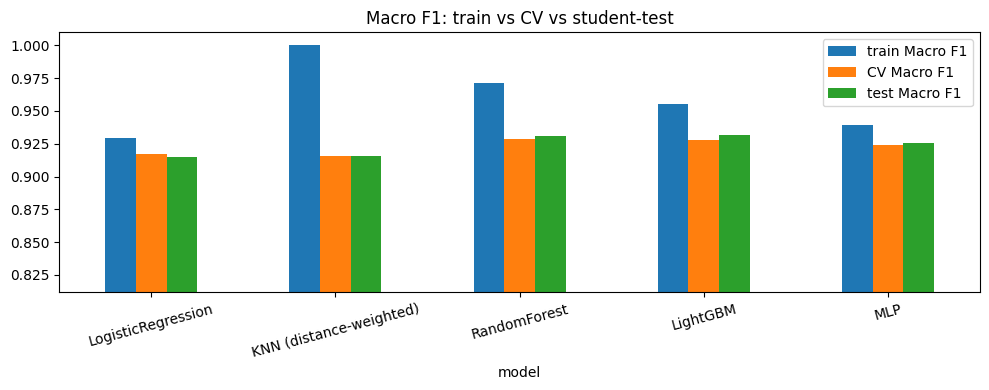

,train Macro F1,CV Macro F1,test Macro F1,train Top-1,CV Top-1,test Top-1
model,,,,,,
LogisticRegression,0.9297,0.9171,0.9146,0.8968,0.8644,0.8738
KNN (distance-weighted),1.0000,0.9157,0.9158,0.9926,0.8616,0.8746
RandomForest,0.9717,0.9286,0.9306,0.9555,0.8764,0.8863
LightGBM,0.9557,0.9276,0.9316,0.9320,0.8744,0.8879
MLP,0.9396,0.9244,0.9254,0.9113,0.8749,0.8814


In [16]:
fit_gap = pd.DataFrame({
    "train Macro F1": test_res["train_macro_f1"], "CV Macro F1": cv_summary["cv_macro_f1"], "test Macro F1": test_res["test_macro_f1"],
    "train Top-1": test_res["train_top1"], "CV Top-1": cv_summary["cv_top1"], "test Top-1": test_res["test_top1"]}).loc[names]
fit_gap.to_csv(RESULTS_DIR / "fit_gap.csv")
ax = fit_gap[["train Macro F1", "CV Macro F1", "test Macro F1"]].plot.bar(figsize=(10, 4), rot=15)
ax.set_ylim(fit_gap.values.min() - .05, 1.01); ax.set_title("Macro F1: train vs CV vs student-test")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fit_gap.png", dpi=120); plt.show()
fit_gap.round(4)

### Confusion matrices (student-test, threshold 0.5)

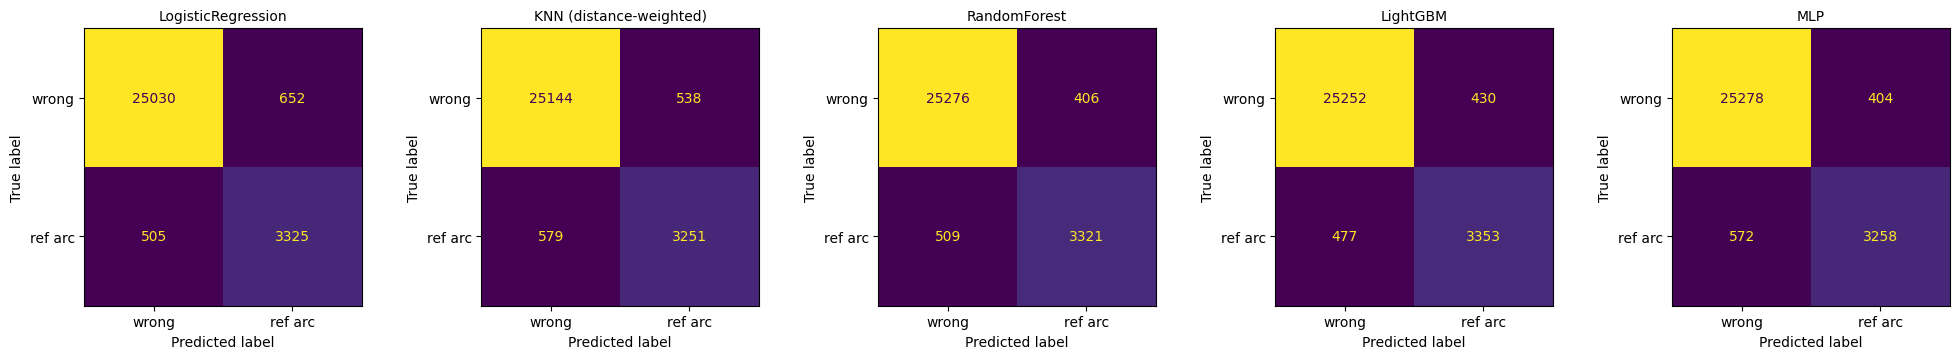

In [17]:
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3.6))
for ax, n in zip(axes, names):
    ConfusionMatrixDisplay(cms[n], display_labels=["wrong", "ref arc"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=120); plt.show()

### Probability quality (calibration)
The HMM uses these probabilities as emission scores, so it matters whether a predicted 0.8 really means "right about 80% of the time". Points close to the diagonal mean well-calibrated probabilities.

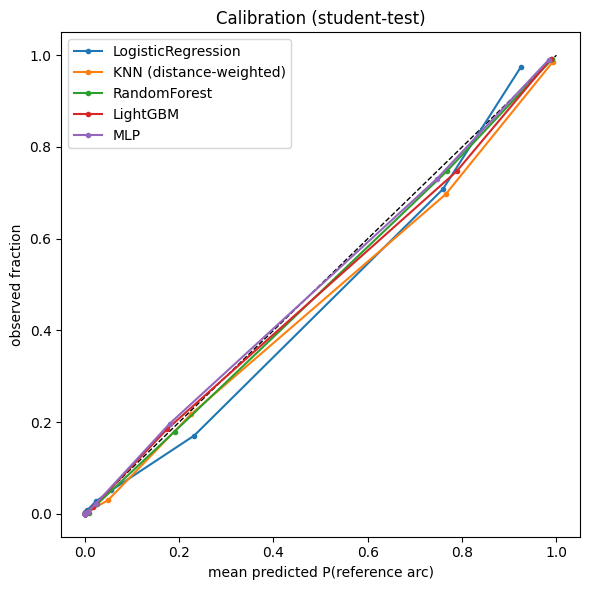

In [18]:
plt.figure(figsize=(6, 6)); plt.plot([0, 1], [0, 1], "k--", lw=1)
for n, c in zip(names, colors):
    fr, mp = calibration_curve(test_df["y"], test_probs[n], n_bins=15, strategy="quantile")
    plt.plot(mp, fr, "o-", color=c, ms=3, label=n)
plt.xlabel("mean predicted P(reference arc)"); plt.ylabel("observed fraction"); plt.legend(); plt.title("Calibration (student-test)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "calibration.png", dpi=120); plt.show()

### Training histories (only for models that actually produce epoch-wise histories)
- **MLP:** trained epoch by epoch with `partial_fit`. Train and validation log loss are computed after each epoch. Validation = 20% of training **trips** (group split).
- **LightGBM:** per-iteration binary log loss on the same group split.

Random Forest, KNN and Logistic Regression (closed-form/solver-based) have no epoch histories, so no curves are drawn for them.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


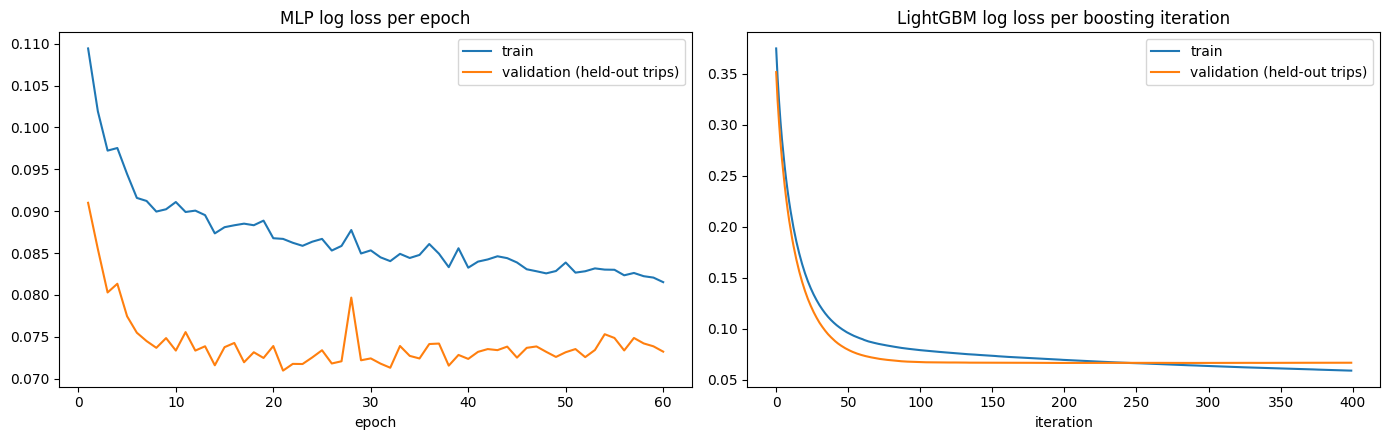

MLP best val epoch: 21 | LightGBM best val iter: 207


In [19]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
h_tr, h_va = next(gss.split(X_tr, y_tr, g_tr))

scaler = StandardScaler().fit(X_tr[h_tr])
Xs_tr, Xs_va = scaler.transform(X_tr[h_tr]), scaler.transform(X_tr[h_va])
mlp = MLPClassifier(**{k.split("__")[1]: v for k, v in MODELS["MLP"][1].get_params().items()
                       if k.startswith("mlpclassifier__")})
mlp.set_params(early_stopping=False)
hist = {"epoch": [], "train": [], "val": []}
classes = np.array([0, 1]); rs = np.random.RandomState(SEED)
for ep in range(60):
    perm = rs.permutation(len(Xs_tr))
    for s in range(0, len(perm), 512):
        b = perm[s:s + 512]; mlp.partial_fit(Xs_tr[b], y_tr[h_tr][b], classes=classes)
    hist["epoch"].append(ep + 1)
    hist["train"].append(log_loss(y_tr[h_tr], mlp.predict_proba(Xs_tr)[:, 1]))
    hist["val"].append(log_loss(y_tr[h_va], mlp.predict_proba(Xs_va)[:, 1]))

lgbm = clone(MODELS["LightGBM"][1])
lgbm.fit(X_tr[h_tr], y_tr[h_tr], eval_set=[(X_tr[h_tr], y_tr[h_tr]), (X_tr[h_va], y_tr[h_va])],
         eval_names=["train", "val"], eval_metric="binary_logloss")
ev = lgbm.evals_result_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hist["epoch"], hist["train"], label="train"); axes[0].plot(hist["epoch"], hist["val"], label="validation (held-out trips)")
axes[0].set_title("MLP log loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ev["train"]["binary_logloss"], label="train"); axes[1].plot(ev["val"]["binary_logloss"], label="validation (held-out trips)")
axes[1].set_title("LightGBM log loss per boosting iteration"); axes[1].set_xlabel("iteration"); axes[1].legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_histories.png", dpi=120); plt.show()
pd.DataFrame(hist).to_csv(RESULTS_DIR / "mlp_history.csv", index=False)
print("MLP best val epoch:", int(np.argmin(hist["val"])) + 1, "| LightGBM best val iter:", int(np.argmin(ev["val"]["binary_logloss"])) + 1)

### Feature importance (tree models)

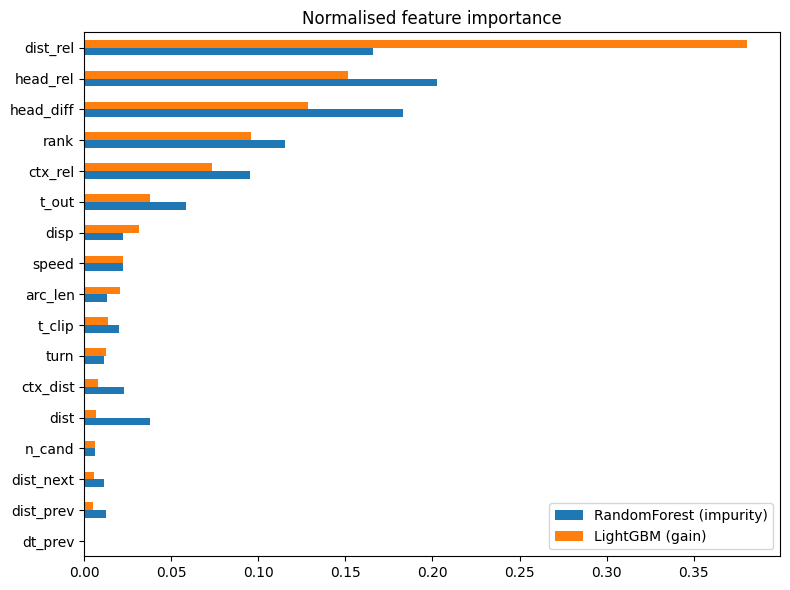

In [20]:
imp = pd.DataFrame({
    "RandomForest (impurity)": fitted["RandomForest"].feature_importances_,
    "LightGBM (gain)": fitted["LightGBM"].booster_.feature_importance("gain"),
}, index=FEATURES)
imp = imp / imp.sum()
imp.sort_values("LightGBM (gain)").plot.barh(figsize=(8, 6)); plt.title("Normalised feature importance")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=120); plt.show()

## 10. Model selection

Rule: **highest mean CV Top-1**. If a model's *paired* per-fold Top-1 difference from the best is within one standard deviation of that difference, the two are treated as tied. In that case, prefer the lower CV log loss (better emission probabilities for the HMM), then the faster inference. Student-test results are shown as a development-stage check, but they do **not** drive the choice. The evaluator partition is never touched.

In [21]:
sel = cv_summary.copy()
best = sel["cv_top1"].idxmax()
# paired per-fold comparison: fold-to-fold variance is dominated by which trips land in a fold,
# so compare each model to the best on the SAME folds.
pv = cv.pivot(index="fold", columns="model", values="top1")
diff = pv.sub(pv[best], axis=0)
sel["paired_diff_vs_best"] = diff.mean()
sel["paired_diff_std"] = diff.std()
contenders = sel[(sel.index == best) | (sel["paired_diff_vs_best"] >= -sel["paired_diff_std"])].copy()
contenders["inference_ms_per_1k_rows"] = test_res.loc[contenders.index, "inference_ms_per_1k_rows"]
contenders = contenders.sort_values(["cv_log_loss", "inference_ms_per_1k_rows"])
selected = contenders.index[0]
print("Ranking by CV Top-1:")
print(sel.sort_values("cv_top1", ascending=False)[["cv_top1", "paired_diff_vs_best", "paired_diff_std", "cv_log_loss", "cv_macro_f1"]].round(4))
print("\nContenders (paired diff within 1 std of best):", list(contenders.index))
print("SELECTED MODEL ->", selected)

joblib.dump(dict(model=fitted[selected], features=FEATURES, config=CFG, name=selected),
            MODELS_DIR / "selected_untuned_model.joblib")
json.dump(dict(selected=selected, rule="max CV Top-1; models within 1 std of paired per-fold difference are tied -> min CV log loss -> faster inference",
               cv=cv_summary.loc[selected].to_dict(), student_test=test_res.loc[selected].drop("family").to_dict()),
          open(RESULTS_DIR / "selection.json", "w"), indent=2, default=float)

Ranking by CV Top-1:
                         cv_top1  paired_diff_vs_best  paired_diff_std  cv_log_loss  cv_macro_f1
model                                                                                           
RandomForest              0.8764               0.0000           0.0000       0.0859       0.9286
MLP                       0.8749              -0.0016           0.0039       0.0893       0.9244
LightGBM                  0.8744              -0.0020           0.0029       0.0849       0.9276
LogisticRegression        0.8644              -0.0120           0.0053       0.1149       0.9171
KNN (distance-weighted)   0.8616              -0.0148           0.0055       0.1333       0.9157

Contenders (paired diff within 1 std of best): ['LightGBM', 'RandomForest', 'MLP']
SELECTED MODEL -> LightGBM


## 11. Folium map: selected model (classifier-only Top-1) on one student-test trip
Layers: raw GPS fixes, reference route, and the Top-1 predicted arcs (red = wrong, orange = correct). No HMM yet, so this shows where the classifier alone produces discontinuities.

In [22]:
import folium

def trip_map(tid, model_name, split="student_test"):
    track, nodes, arcs, route = load_trip(split, tid)
    top = test_tops[model_name].query("trip == @tid")
    fm = folium.Map(location=[track[:, 1].mean(), track[:, 0].mean()], zoom_start=15, tiles="cartodbpositron")
    g_gps = folium.FeatureGroup("GPS fixes (raw)")
    for lon, lat in track[::SAMPLE_EVERY, :2]:
        folium.CircleMarker([lat, lon], radius=2, color="blue", fill=True, opacity=.6).add_to(g_gps)
    g_ref = folium.FeatureGroup("Reference route")
    for a in route:
        folium.PolyLine([[nodes[arcs[a, 0], 1], nodes[arcs[a, 0], 0]], [nodes[arcs[a, 1], 1], nodes[arcs[a, 1], 0]]],
                        color="green", weight=6, opacity=.6).add_to(g_ref)
    g_pred = folium.FeatureGroup(f"Top-1 prediction ({model_name})")
    for a, y in top[["arc", "y"]].drop_duplicates().values:
        folium.PolyLine([[nodes[arcs[a, 0], 1], nodes[arcs[a, 0], 0]], [nodes[arcs[a, 1], 1], nodes[arcs[a, 1], 0]]],
                        color="orange" if y else "red", weight=3).add_to(g_pred)
    for g in (g_ref, g_pred, g_gps): g.add_to(fm)
    folium.LayerControl(collapsed=False).add_to(fm)
    fm.fit_bounds([[track[:, 1].min(), track[:, 0].min()], [track[:, 1].max(), track[:, 0].max()]])
    return fm

map_trip = per_trip_all[selected].idxmin()   # hardest student-test trip for the selected model
fm = trip_map(map_trip, selected)
(RESULTS_DIR / "maps").mkdir(exist_ok=True)
fm.save(RESULTS_DIR / "maps" / f"student_test_{map_trip}_{selected.replace(' ', '_')}_top1.html")
print("Trip", map_trip, "Top-1 =", round(per_trip_all[selected][map_trip], 4))
fm

Trip 00000077 Top-1 = 0.7356
